In [1]:
cd /home/lihaoxing/scRNAseq/cytotrace2

/home/lihaoxing/scRNAseq/cytotrace2



样本: IVF_2C

[iDEG vs DPA]
共有细胞数: 42
直接一致性: 0.5714
交换后一致性: 0.4286
最大一致性: 0.5714
最佳标签对应: 0↔0, 1↔1
ARI: -0.0026
NMI: 0.0110

[iDET vs iDEG]
共有细胞数: 42
直接一致性: 0.6429
交换后一致性: 0.3571
最大一致性: 0.6429
最佳标签对应: 0↔0, 1↔1
ARI: 0.0574
NMI: 0.0412

[iDET vs DPA]
共有细胞数: 42
直接一致性: 0.5952
交换后一致性: 0.4048
最大一致性: 0.5952
最佳标签对应: 0↔0, 1↔1
ARI: 0.0133
NMI: 0.0223

样本: IVF_4C

[iDEG vs DPA]
共有细胞数: 60
直接一致性: 0.7833
交换后一致性: 0.2167
最大一致性: 0.7833
最佳标签对应: 0↔0, 1↔1
ARI: 0.3116
NMI: 0.3831

[iDET vs iDEG]
共有细胞数: 60
直接一致性: 0.3167
交换后一致性: 0.6833
最大一致性: 0.6833
最佳标签对应: 0↔1, 1↔0
ARI: 0.1195
NMI: 0.2783

[iDET vs DPA]
共有细胞数: 60
直接一致性: 0.2000
交换后一致性: 0.8000
最大一致性: 0.8000
最佳标签对应: 0↔1, 1↔0
ARI: 0.3492
NMI: 0.3032

样本: PA_2C

[iDEG vs DPA]
共有细胞数: 24
直接一致性: 0.8750
交换后一致性: 0.1250
最大一致性: 0.8750
最佳标签对应: 0↔0, 1↔1
ARI: 0.5413
NMI: 0.5289

[iDET vs iDEG]
共有细胞数: 21
直接一致性: 1.0000
交换后一致性: 0.0000
最大一致性: 1.0000
最佳标签对应: 0↔0, 1↔1
ARI: 1.0000
NMI: 1.0000

[iDET vs DPA]
共有细胞数: 21
直接一致性: 0.9048
交换后一致性: 0.0952
最大一致性: 0.9048
最佳标签对应: 0↔0, 1↔1
ARI:

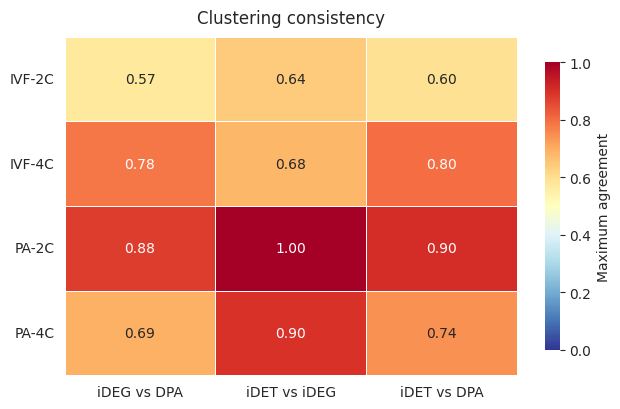


热图已保存: cluster_agreement_heatmap.svg


In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score


# ============================================================
# 0. 全局设置
# ============================================================

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["svg.hashsalt"] = "hello"

# 输入文件所在目录；当前目录使用 "."
INPUT_DIR = "."

# 输出文件
OUTPUT_HEATMAP = "cluster_agreement_heatmap.svg"
OUTPUT_MATRIX = "cluster_agreement_matrix.tsv"
OUTPUT_DETAILS = "cluster_agreement_details.tsv"

# 样本
SAMPLES = ["IVF_2C", "IVF_4C", "PA_2C", "PA_4C"]

# 三种分类结果文件后缀
# 根据你的实际文件名修改这里即可
FILE_SUFFIXES = {
    "iDEG": "_dip_seed99.txt",
    "iDET": "_iDET-copy_seed99.txt",
    "DPA": "_dpa_seed99.txt",
}

# 热图比较顺序
COMPARISONS = [
    ("iDEG", "DPA"),
    ("iDET", "iDEG"),
    ("iDET", "DPA"),
]


# ============================================================
# 1. 读取分类结果
# ============================================================

def load_clusters(filename):
    """
    读取制表符分隔的分类文件。

    默认文件格式：
    cell_id    cluster    feature1    feature2    feature3

    只读取前两列，其余列不参与分类一致性计算。
    """

    if not os.path.isfile(filename):
        raise FileNotFoundError(f"找不到文件: {filename}")

    df = pd.read_csv(
        filename,
        sep="\t",
        header=None,
        usecols=[0, 1],
        names=["cell_id", "cluster"],
        dtype={"cell_id": str}
    )

    df = df.dropna(subset=["cell_id", "cluster"]).copy()

    # 检查重复细胞 ID，避免一个细胞对应多个分类标签
    duplicated = df["cell_id"].duplicated(keep=False)
    if duplicated.any():
        duplicate_ids = df.loc[duplicated, "cell_id"].unique()[:10]
        raise ValueError(
            f"{filename} 中存在重复 cell_id，例如: "
            f"{duplicate_ids.tolist()}"
        )

    # 检查分类标签
    observed_labels = set(df["cluster"].unique())
    if observed_labels != {0, 1}:
        raise ValueError(
            f"{filename} 的分类标签应为 0 和 1，"
            f"实际读取到: {observed_labels}"
        )

    return df.set_index("cell_id")["cluster"].astype(int)


# ============================================================
# 2. 比较两组分类结果
# ============================================================

def compare_clusters(file1, file2, label1, label2):
    """
    比较两组二分类结果。

    最大一致性 = max(
        直接标签匹配比例,
        标签互换后的匹配比例
    )

    同时计算 ARI 和 NMI。
    """

    c1 = load_clusters(file1)
    c2 = load_clusters(file2)

    # 按 cell_id 对齐，仅比较共有细胞
    common_cells = c1.index.intersection(c2.index)

    if len(common_cells) == 0:
        raise ValueError(
            f"{label1} 与 {label2} 没有共有细胞，"
            "请检查两个文件中的 cell_id。"
        )

    c1 = c1.loc[common_cells]
    c2 = c2.loc[common_cells]

    n_total = len(common_cells)

    # 直接匹配：0 对 0，1 对 1
    agreement_direct = (c1 == c2).mean()

    # 标签互换：0 对 1，1 对 0
    c2_swapped = c2.map({0: 1, 1: 0})
    agreement_swapped = (c1 == c2_swapped).mean()

    # 取最大一致性，消除聚类标签命名差异
    if agreement_direct >= agreement_swapped:
        max_agreement = agreement_direct
        best_mapping = "0↔0, 1↔1"
    else:
        max_agreement = agreement_swapped
        best_mapping = "0↔1, 1↔0"

    # ARI 和 NMI 不受聚类标签置换影响
    ari = adjusted_rand_score(c1, c2)
    nmi = normalized_mutual_info_score(c1, c2)

    return {
        "comparison": f"{label1} vs {label2}",
        "n_cells": n_total,
        "agreement_direct": agreement_direct,
        "agreement_swapped": agreement_swapped,
        "max_agreement": max_agreement,
        "ARI": ari,
        "NMI": nmi,
        "best_mapping": best_mapping,
        "group1_cluster0": int((c1 == 0).sum()),
        "group1_cluster1": int((c1 == 1).sum()),
        "group2_cluster0": int((c2 == 0).sum()),
        "group2_cluster1": int((c2 == 1).sum()),
    }


# ============================================================
# 3. 批量比较所有样本
# ============================================================

results = {}
detail_rows = []

for sample in SAMPLES:

    print("\n" + "=" * 72)
    print(f"样本: {sample}")
    print("=" * 72)

    files = {
        name: os.path.join(INPUT_DIR, sample + suffix)
        for name, suffix in FILE_SUFFIXES.items()
    }

    results[sample] = {}

    for name1, name2 in COMPARISONS:

        result = compare_clusters(
            files[name1],
            files[name2],
            name1,
            name2
        )

        comparison_key = f"{name1} vs {name2}"
        results[sample][comparison_key] = result

        detail_rows.append({
            "sample": sample,
            **result
        })

        print(f"\n[{name1} vs {name2}]")
        print(f"共有细胞数: {result['n_cells']}")
        print(f"直接一致性: {result['agreement_direct']:.4f}")
        print(f"交换后一致性: {result['agreement_swapped']:.4f}")
        print(f"最大一致性: {result['max_agreement']:.4f}")
        print(f"最佳标签对应: {result['best_mapping']}")
        print(f"ARI: {result['ARI']:.4f}")
        print(f"NMI: {result['NMI']:.4f}")


# ============================================================
# 4. 构建并打印一致性矩阵
# ============================================================

comparison_columns = [
    f"{name1} vs {name2}"
    for name1, name2 in COMPARISONS
]

agreement_matrix = pd.DataFrame(
    {
        sample: [
            results[sample][comparison]["max_agreement"]
            for comparison in comparison_columns
        ]
        for sample in SAMPLES
    },
    index=comparison_columns
).T

# 将行列名称格式化
agreement_matrix.index = [
    sample.replace("_", "-")
    for sample in agreement_matrix.index
]

print("\n" + "=" * 72)
print("最大分类一致性矩阵")
print("=" * 72)
print(agreement_matrix.round(4).to_string())

agreement_matrix.to_csv(
    OUTPUT_MATRIX,
    sep="\t",
    float_format="%.6f"
)


# ============================================================
# 5. 输出全部比较指标
# ============================================================

details_df = pd.DataFrame(detail_rows)

details_df.to_csv(
    OUTPUT_DETAILS,
    sep="\t",
    index=False,
    float_format="%.6f"
)

print(f"\n详细指标已保存: {OUTPUT_DETAILS}")
print(f"一致性矩阵已保存: {OUTPUT_MATRIX}")


# ============================================================
# 6. 绘制一致性热图
# ============================================================

sns.set_style("white")

fig, ax = plt.subplots(figsize=(6.5, 4.2))

sns.heatmap(
    agreement_matrix,
    cmap="RdYlBu_r",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    square=False,
    cbar_kws={
        "label": "Maximum agreement",
        "shrink": 0.85
    },
    annot_kws={
        "size": 10
    },
    ax=ax
)

ax.set_title("Clustering consistency", fontsize=12, pad=10)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()

plt.savefig(
    OUTPUT_HEATMAP,
    format="svg",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close(fig)

print(f"\n热图已保存: {OUTPUT_HEATMAP}")


In [4]:

import os
import re
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score


# ============================================================
# 0. 参数设置
# ============================================================

INPUT_FILE = "PA_IVF_198_CytoTRACE2_results_cluster2_dip.txt"
OUTPUT_DIR = "cluster_consistency_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["svg.hashsalt"] = "hello"

# 样本分组列与细胞 ID 列
CELL_ID_COL = "ID"
STAGE_COL = "Phenotype"

# 已有分类特征
METHOD_COLUMNS = {
    "iDEG": "Phenotype2",
    "iDET-family": "iDET-family",
    "iDET-copy": "iDET-copy",

    # 下面为单独的 TE 家族/重复序列分类
    "DNA-hAT-Charlie": "DNA-hAT-Charlie",
    "LINE-L1": "LINE-L1",
    "LINE-L2": "LINE-L2",
    "LTR-ERV1": "LTR-ERV1",
    "LTR-ERVL-MaLR": "LTR-ERVL-MaLR",
    "LTR-ERVL": "LTR-ERVL",
    #"Low_complexity": "Low_complexity",
    "SINE-MIR": "SINE-MIR",
    "SINE-tRNA": "SINE-tRNA",
    "Simple_repeat": "Simple_repeat",
}

# 注意：你给出的表头没有独立的 DPA 分类列。
# 如果完整文件中确实存在 DPA 分类列，在这里填写真实列名。
# 如果没有，就保持 None；不要用 CytoTRACE2 分数自动替代 DPA 分类。
DPA_COL = None

if DPA_COL is not None:
    METHOD_COLUMNS = {"DPA": DPA_COL, **METHOD_COLUMNS}

# 热图中显示的样本顺序
SAMPLE_ORDER = ["IVF-2C", "IVF-4C", "PA-2C", "PA-4C"]


# ============================================================
# 1. 读取总表
# ============================================================

df = pd.read_csv(INPUT_FILE, sep="\t", dtype={CELL_ID_COL: str})

required_cols = [CELL_ID_COL, STAGE_COL] + list(METHOD_COLUMNS.values())
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"输入文件缺少以下列: {missing_cols}")

if df[CELL_ID_COL].duplicated().any():
    duplicated_ids = df.loc[
        df[CELL_ID_COL].duplicated(keep=False), CELL_ID_COL
    ].unique()[:10]
    raise ValueError(
        f"细胞 ID 不唯一，例如: {duplicated_ids.tolist()}"
    )

df[STAGE_COL] = df[STAGE_COL].astype(str)

print("=" * 80)
print("输入数据概况")
print("=" * 80)
print(f"总细胞数: {len(df)}")
print(f"分类特征数: {len(METHOD_COLUMNS)}")
print("分类特征:", list(METHOD_COLUMNS.keys()))
print("\n各样本细胞数:")
print(df[STAGE_COL].value_counts().to_string())


# ============================================================
# 2. 分类标签编码
# ============================================================

def encode_binary_labels(series, method_name):
    """
    将任意两个分类标签编码为 0/1。
    标签名称可以是 IVF-2C-iDEG1/2、
    IVF-2C-iDET1/2 等。

    两种分类之间会进一步计算标签互换后的最大一致性，
    因此不同特征的标签命名不需要相同。
    """

    valid = series.dropna()
    unique_labels = list(pd.unique(valid))

    if len(unique_labels) != 2:
        raise ValueError(
            f"{method_name} 应有两个分类，"
            f"但实际检测到 {len(unique_labels)} 个: {unique_labels}"
        )

    mapping = {unique_labels[0]: 0, unique_labels[1]: 1}

    return series.map(mapping)


# ============================================================
# 3. 两种分类结果的一致性
# ============================================================

def compare_two_methods(df_sample, method1, method2):
    """
    只使用两个特征均有有效分类标签的共有细胞。

    输出：
    - 最大一致性
    - 直接一致性
    - 标签互换后的一致性
    - ARI
    - NMI
    - 共有细胞数
    """

    col1 = METHOD_COLUMNS[method1]
    col2 = METHOD_COLUMNS[method2]

    sub = df_sample[[CELL_ID_COL, col1, col2]].dropna().copy()

    n = len(sub)

    if n == 0:
        raise ValueError(
            f"{method1} 和 {method2} 没有共有的有效分类细胞。"
        )

    c1 = encode_binary_labels(sub[col1], method1)
    c2 = encode_binary_labels(sub[col2], method2)

    # 直接对应
    direct = float((c1 == c2).mean())

    # 交换 0/1 标签后对应
    swapped = float((c1 == (1 - c2)).mean())

    maximum = max(direct, swapped)

    mapping = (
        "direct"
        if direct >= swapped
        else "swapped"
    )

    ari = adjusted_rand_score(c1, c2)
    nmi = normalized_mutual_info_score(c1, c2)

    return {
        "n_cells": n,
        "direct_agreement": direct,
        "swapped_agreement": swapped,
        "max_agreement": maximum,
        "best_mapping": mapping,
        "ARI": ari,
        "NMI": nmi,
    }


# ============================================================
# 4. 分别分析 IVF-2C / IVF-4C / PA-2C / PA-4C
# ============================================================

all_results = []
matrices = {}

methods = list(METHOD_COLUMNS.keys())
pairs = list(itertools.combinations(methods, 2))

for sample in SAMPLE_ORDER:

    df_sample = df.loc[df[STAGE_COL] == sample].copy()

    if df_sample.empty:
        print(f"\n警告：没有找到样本 {sample}，跳过。")
        continue

    print("\n" + "=" * 80)
    print(f"样本: {sample}")
    print(f"细胞数: {len(df_sample)}")
    print("=" * 80)

    # 一致性矩阵：对角线为 1
    matrix = pd.DataFrame(
        np.eye(len(methods)),
        index=methods,
        columns=methods
    )

    # ARI 矩阵
    ari_matrix = pd.DataFrame(
        np.eye(len(methods)),
        index=methods,
        columns=methods
    )

    # NMI 矩阵
    nmi_matrix = pd.DataFrame(
        np.eye(len(methods)),
        index=methods,
        columns=methods
    )

    for method1, method2 in pairs:

        result = compare_two_methods(
            df_sample,
            method1,
            method2
        )

        matrix.loc[method1, method2] = result["max_agreement"]
        matrix.loc[method2, method1] = result["max_agreement"]

        ari_matrix.loc[method1, method2] = result["ARI"]
        ari_matrix.loc[method2, method1] = result["ARI"]

        nmi_matrix.loc[method1, method2] = result["NMI"]
        nmi_matrix.loc[method2, method1] = result["NMI"]

        all_results.append({
            "sample": sample,
            "method1": method1,
            "method2": method2,
            **result
        })

    matrices[sample] = {
        "agreement": matrix,
        "ARI": ari_matrix,
        "NMI": nmi_matrix,
    }

    # --------------------------------------------------------
    # 打印完整一致性矩阵
    # --------------------------------------------------------

    print("\n最大一致性矩阵:")
    print(matrix.round(3).to_string())

    print("\nARI 矩阵:")
    print(ari_matrix.round(3).to_string())

    print("\nNMI 矩阵:")
    print(nmi_matrix.round(3).to_string())

    # --------------------------------------------------------
    # 保存矩阵
    # --------------------------------------------------------

    sample_prefix = sample.replace("-", "_")

    matrix.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{sample_prefix}_agreement_matrix.tsv"
        ),
        sep="\t",
        float_format="%.6f"
    )

    ari_matrix.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{sample_prefix}_ARI_matrix.tsv"
        ),
        sep="\t",
        float_format="%.6f"
    )

    nmi_matrix.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{sample_prefix}_NMI_matrix.tsv"
        ),
        sep="\t",
        float_format="%.6f"
    )

    # --------------------------------------------------------
    # 绘制最大一致性热图
    # --------------------------------------------------------

    fig_size = max(9, len(methods) * 0.75)

    fig, ax = plt.subplots(
        figsize=(fig_size, fig_size * 0.82)
    )

    sns.heatmap(
        matrix,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=1,
        annot=True,
        fmt=".2f",
        square=True,
        linewidths=0.4,
        linecolor="white",
        annot_kws={"size": 8},
        cbar_kws={"label": "Maximum agreement"},
        ax=ax
    )

    ax.set_title(
        f"{sample}: clustering consistency",
        fontsize=13,
        pad=12
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=45, labelsize=9)
    ax.tick_params(axis="y", labelrotation=0, labelsize=9)

    plt.tight_layout()

    heatmap_file = os.path.join(
        OUTPUT_DIR,
        f"{sample_prefix}_agreement_heatmap.svg"
    )

    plt.savefig(
        heatmap_file,
        format="svg",
        dpi=300,
        bbox_inches="tight",
        transparent=True
    )

    plt.close(fig)

    print(f"\n已保存热图: {heatmap_file}")


# ============================================================
# 5. 汇总所有样本的两两比较结果
# ============================================================

details = pd.DataFrame(all_results)

details.to_csv(
    os.path.join(OUTPUT_DIR, "all_pairwise_comparison_details.tsv"),
    sep="\t",
    index=False,
    float_format="%.6f"
)

print("\n" + "=" * 80)
print("所有样本的两两比较结果")
print("=" * 80)

if not details.empty:
    display_cols = [
        "sample",
        "method1",
        "method2",
        "n_cells",
        "max_agreement",
        "ARI",
        "NMI",
        "best_mapping"
    ]

    print(
        details[display_cols]
        .sort_values(["sample", "max_agreement"], ascending=[True, False])
        .to_string(index=False)
    )

print(f"\n全部输出文件保存在目录: {OUTPUT_DIR}")


输入数据概况
总细胞数: 165
分类特征数: 12
分类特征: ['iDEG', 'iDET-family', 'iDET-copy', 'DNA-hAT-Charlie', 'LINE-L1', 'LINE-L2', 'LTR-ERV1', 'LTR-ERVL-MaLR', 'LTR-ERVL', 'SINE-MIR', 'SINE-tRNA', 'Simple_repeat']

各样本细胞数:
Phenotype
IVF-4C    60
IVF-2C    42
PA-4C     39
PA-2C     24

样本: IVF-2C
细胞数: 42

最大一致性矩阵:
                  iDEG  iDET-family  iDET-copy  DNA-hAT-Charlie  LINE-L1  LINE-L2  LTR-ERV1  LTR-ERVL-MaLR  LTR-ERVL  SINE-MIR  SINE-tRNA  Simple_repeat
iDEG             1.000        0.571      0.643            0.667    0.524    0.548     0.548          0.619     0.643     0.667      0.548          0.595
iDET-family      0.571        1.000      0.643            0.619    0.571    0.595     0.786          0.524     0.548     0.667      0.595          0.595
iDET-copy        0.643        0.643      1.000            0.929    0.786    0.619     0.667          0.833     0.905     0.929      0.571          0.905
DNA-hAT-Charlie  0.667        0.619      0.929            1.000    0.762    0.643     0.595  


已保存热图: cluster_consistency_results/IVF_4C_agreement_heatmap.svg

样本: PA-2C
细胞数: 24

最大一致性矩阵:
                  iDEG  iDET-family  iDET-copy  DNA-hAT-Charlie  LINE-L1  LINE-L2  LTR-ERV1  LTR-ERVL-MaLR  LTR-ERVL  SINE-MIR  SINE-tRNA  Simple_repeat
iDEG             1.000        0.875      1.000            0.958    0.667    0.708     0.708          0.625     1.000     0.958      0.625          0.708
iDET-family      0.875        1.000      0.875            0.833    0.625    0.667     0.667          0.667     0.875     0.833      0.750          0.667
iDET-copy        1.000        0.875      1.000            0.958    0.667    0.708     0.708          0.625     1.000     0.958      0.625          0.708
DNA-hAT-Charlie  0.958        0.833      0.958            1.000    0.708    0.667     0.750          0.583     0.958     1.000      0.583          0.750
LINE-L1          0.667        0.625      0.667            0.708    1.000    0.542     0.625          0.625     0.667     0.708      0.875    


已保存热图: cluster_consistency_results/PA_4C_agreement_heatmap.svg

所有样本的两两比较结果
sample         method1         method2  n_cells  max_agreement       ARI      NMI best_mapping
IVF-2C        LTR-ERVL   Simple_repeat       42       0.952381  0.814155 0.768199       direct
IVF-2C       iDET-copy DNA-hAT-Charlie       42       0.928571  0.727680 0.618872       direct
IVF-2C       iDET-copy        SINE-MIR       42       0.928571  0.727081 0.677780       direct
IVF-2C       iDET-copy        LTR-ERVL       42       0.904762  0.646964 0.552837       direct
IVF-2C       iDET-copy   Simple_repeat       42       0.904762  0.647184 0.628424       direct
IVF-2C DNA-hAT-Charlie        SINE-MIR       42       0.904762  0.644304 0.532350       direct
IVF-2C DNA-hAT-Charlie        LTR-ERVL       42       0.880952  0.570356 0.488160       direct
IVF-2C DNA-hAT-Charlie   Simple_repeat       42       0.880952  0.570828 0.571494       direct
IVF-2C   LTR-ERVL-MaLR        LTR-ERVL       42       0.880952  0.57